# Preliminaries

## Data Import

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
from sklearn.exceptions import ConvergenceWarning

# Ignore only ConvergenceWarning (not all warnings)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/gallstone/dataset-uci.csv')
df.head()

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


In [ ]:
df.columns

Index(['Gallstone Status', 'Age', 'Gender', 'Comorbidity',
       'Coronary Artery Disease (CAD)', 'Hypothyroidism', 'Hyperlipidemia',
       'Diabetes Mellitus (DM)', 'Height', 'Weight', 'Body Mass Index (BMI)',
       'Total Body Water (TBW)', 'Extracellular Water (ECW)',
       'Intracellular Water (ICW)',
       'Extracellular Fluid/Total Body Water (ECF/TBW)',
       'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)',
       'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)',
       'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)',
       'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)',
       'Visceral Muscle Area (VMA) (Kg)', 'Hepatic Fat Accumulation (HFA)',
       'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)',
       'High Density Lipoprotein (HDL)', 'Triglyceride',
       'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)',
       'Alkaline Phosphatase (ALP)', 'Creatinine',
       'Glomerular Filtration Rate (GFR

In [ ]:
numerical_columns = numerical_columns = [
    'Age', 'Height', 'Weight', 'Body Mass Index (BMI)',
    'Total Body Water (TBW)', 'Extracellular Water (ECW)',
    'Intracellular Water (ICW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)',
    'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)',
    'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)',
    'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)',
    'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)',
    'Visceral Muscle Area (VMA) (Kg)', 'Hepatic Fat Accumulation (HFA)',
    'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)',
    'High Density Lipoprotein (HDL)', 'Triglyceride',
    'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)',
    'Alkaline Phosphatase (ALP)', 'Creatinine',
    'Glomerular Filtration Rate (GFR)', 'C-Reactive Protein (CRP)',
    'Hemoglobin (HGB)', 'Vitamin D'
]


## Preprocessing

In [ ]:
df['Gallstone Status']

,Gallstone Status
0,0
1,0
2,0
3,0
4,0
...,...
314,1
315,1
316,1
317,1


In [ ]:
X = df.drop(['Gallstone Status'], axis=1)
y = df['Gallstone Status']

In [ ]:
display(y.value_counts())

,count
Gallstone Status,
0,161
1,158


### Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X_train_df = pd.DataFrame(X_train, columns=X.columns)
X_test_df = pd.DataFrame(X_test, columns=X.columns)

In [ ]:
X_train_df.head()

,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,Body Mass Index (BMI),...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
210,39,1,1,0,0,0,0,165,74.0,27.2,...,63.0,94.0,19.0,19.0,49.0,0.58,117.90,0.00,11.9,9.500
76,20,0,0,0,0,0,0,188,62.8,17.8,...,60.0,52.0,25.0,7.0,7.0,0.93,117.75,0.00,16.0,19.625
94,49,1,1,0,1,0,0,158,92.5,37.1,...,57.0,82.0,18.0,18.0,92.0,0.63,109.77,0.78,10.7,21.800
222,31,1,0,0,0,0,0,158,100.8,40.4,...,48.0,116.0,17.0,18.0,106.0,0.72,114.50,7.00,12.2,24.000
311,47,1,0,0,0,0,0,158,63.6,25.5,...,47.0,67.0,16.0,17.0,75.0,0.59,118.20,0.15,13.9,15.700


### Log Transform

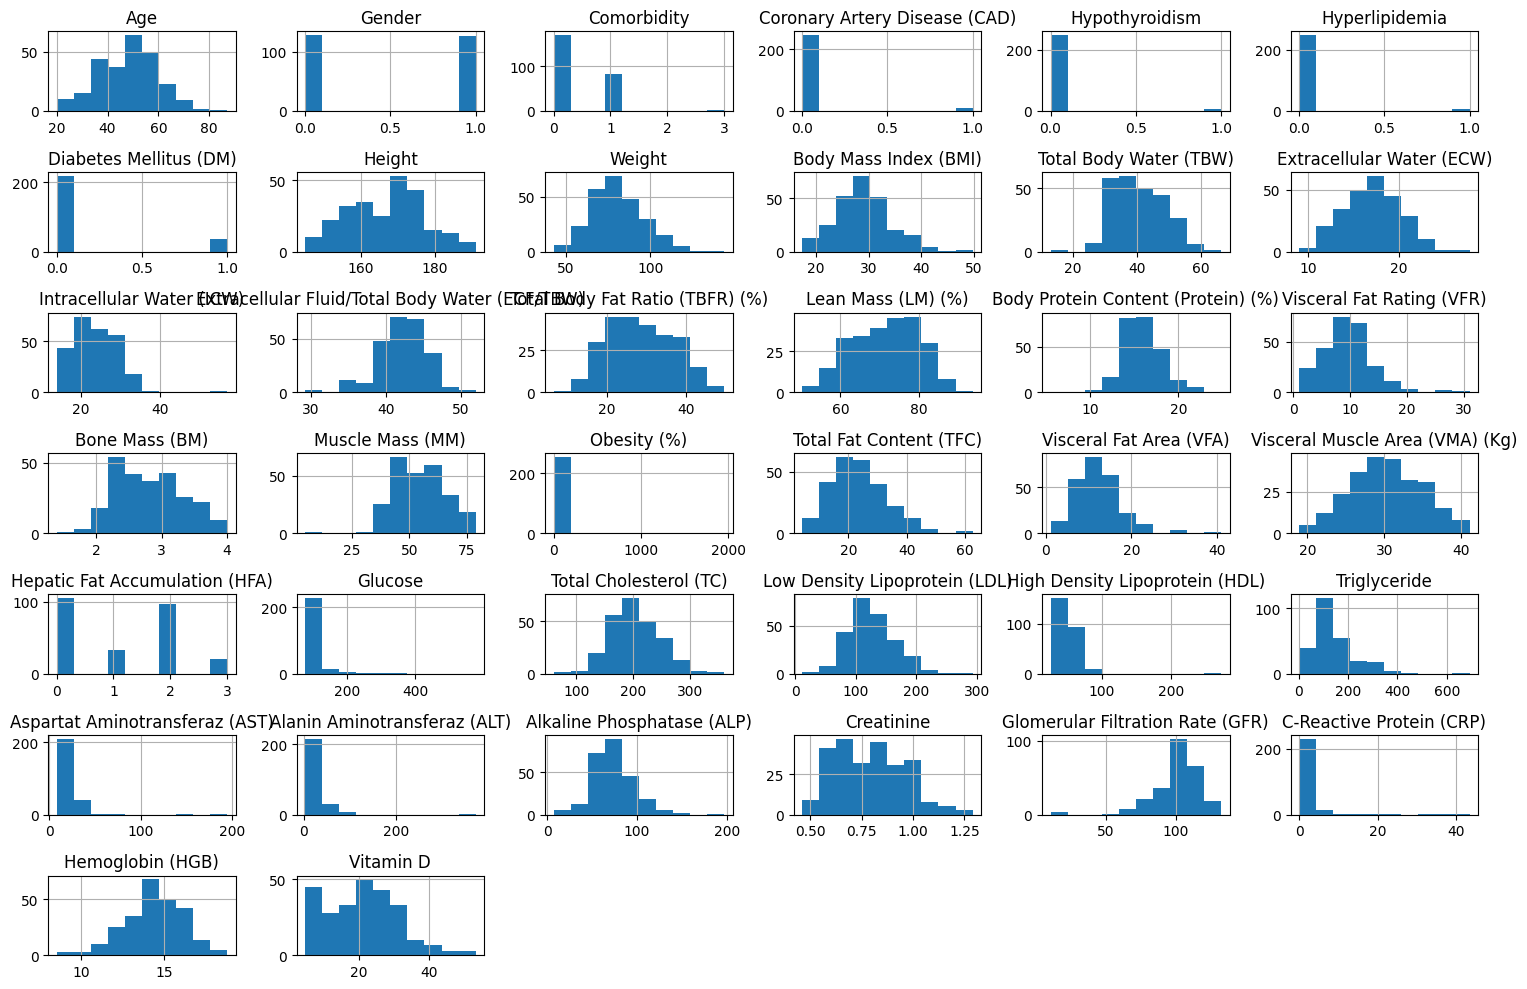

In [ ]:
# Draw histograms for each feature in X_train_df
X_train_df.hist(figsize=(15, 10))
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import skew

# Identify numerical columns (assuming they are all in X_train_df)
numerical_cols_df = X_train_df.select_dtypes(include=np.number).columns

# Calculate skewness for numerical features in the training data
skewness = X_train_df[numerical_cols_df].apply(lambda x: skew(x.dropna()))

# Define a skewness threshold
skewness_threshold = 0.4

# Identify skewed features
skewed_features = skewness[abs(skewness) > skewness_threshold].index

# Apply log transformation to skewed features in both training and testing data
for feature in skewed_features:
    # Add 1 to the feature values before taking the log to handle zero values
    X_train_df[feature] = np.log1p(X_train_df[feature])
    X_test_df[feature] = np.log1p(X_test_df[feature])

print(f"Applied log transformation to the following skewed features (skewness threshold > {skewness_threshold}):")
print(list(skewed_features))

Applied log transformation to the following skewed features (skewness threshold > 0.4):
['Comorbidity', 'Coronary Artery Disease (CAD)', 'Hypothyroidism', 'Hyperlipidemia', 'Diabetes Mellitus (DM)', 'Weight', 'Body Mass Index (BMI)', 'Intracellular Water (ICW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Visceral Fat Rating (VFR)', 'Obesity (%)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Alkaline Phosphatase (ALP)', 'Glomerular Filtration Rate (GFR)', 'C-Reactive Protein (CRP)', 'Hemoglobin (HGB)']


### Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_log = StandardScaler()
X_train_scaled_log = scaler_log.fit_transform(X_train_df)
X_test_scaled_log = scaler_log.transform(X_test_df)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled_log = pd.DataFrame(X_train_scaled_log, columns=X.columns)
X_test_scaled_log = pd.DataFrame(X_test_scaled_log, columns=X.columns)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

### Removing Correlation

In [ ]:
#@title Function to remove Highly Correlated Features

import matplotlib.pyplot as plt
import seaborn as sns

def remove_highly_correlated_features(X_train_scaled, X_test_scaled, numerical_columns, threshold=0.8, plot=True):
    """
    Removes highly correlated features from the training and test datasets.

    Parameters:
        X_train_scaled (pd.DataFrame): Scaled training dataset.
        X_test_scaled (pd.DataFrame): Scaled test dataset.
        numerical_columns (list): List of numerical feature names.
        threshold (float): Correlation threshold for removing features. Default is 0.8.
        plot (bool): Whether to display a correlation heatmap. Default is True.

    Returns:
        X_train_uncor (pd.DataFrame): Training dataset with uncorrelated features.
        X_test_uncor (pd.DataFrame): Test dataset with uncorrelated features.
    """

    # Calculate the correlation matrix
    correlation_matrix = X_train_scaled[numerical_columns].corr()

    # Plot correlation heatmap
    if plot:
        plt.figure(figsize=(12, 10))
        sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
        plt.title('Correlation Matrix of Numerical Features')
        plt.tight_layout()
        plt.show()

    # Find highly correlated pairs
    high_corr_pairs = []
    for i in range(len(correlation_matrix.columns)):
        for j in range(i):
            corr_value = correlation_matrix.iloc[i, j]
            if abs(corr_value) > threshold:
                col_i = correlation_matrix.columns[i]
                col_j = correlation_matrix.columns[j]
                high_corr_pairs.append((col_i, col_j, corr_value))

    # Print results
    if high_corr_pairs:
        print(f"Highly correlated feature pairs (|corr| > {threshold}):")
        for pair in high_corr_pairs:
            print(f"{pair[0]} - {pair[1]}: {pair[2]:.2f}")
    else:
        print(f"No feature pairs found with |corr| > {threshold}.")

    # Determine features to drop (drop the second feature in each pair)
    features_to_drop = {pair[1] for pair in high_corr_pairs}

    # Remove correlated features
    X_train_uncor = X_train_scaled.drop(columns=features_to_drop, errors='ignore')
    X_test_uncor = X_test_scaled.drop(columns=features_to_drop, errors='ignore')

    print(f"\nOriginal number of features: {X_train_scaled.shape[1]}")
    print(f"Number of features after dropping highly correlated: {X_train_uncor.shape[1]}")

    return X_train_uncor, X_test_uncor


In [ ]:
# Removing correlation from log transformed data
X_train_log_uncor, X_test_log_uncor = remove_highly_correlated_features(X_train_scaled_log, X_test_scaled_log, numerical_columns, threshold=0.9, plot=False)

Highly correlated feature pairs (|corr| > 0.9):
Extracellular Water (ECW) - Total Body Water (TBW): 0.90
Lean Mass (LM) (%) - Total Body Fat Ratio (TBFR) (%): -1.00
Muscle Mass (MM) - Total Body Water (TBW): 0.92
Muscle Mass (MM) - Intracellular Water (ICW): 0.92

Original number of features: 38
Number of features after dropping highly correlated: 35


In [ ]:
# Removing correlation from non-log transformed data
X_train_uncor, X_test_uncor = remove_highly_correlated_features(X_train_scaled, X_test_scaled, numerical_columns, threshold=0.8, plot=False)

Highly correlated feature pairs (|corr| > 0.8):
Extracellular Water (ECW) - Total Body Water (TBW): 0.90
Lean Mass (LM) (%) - Total Body Fat Ratio (TBFR) (%): -1.00
Bone Mass (BM) - Total Body Water (TBW): 0.83
Bone Mass (BM) - Extracellular Water (ECW): 0.82
Muscle Mass (MM) - Total Body Water (TBW): 0.92
Muscle Mass (MM) - Extracellular Water (ECW): 0.86
Muscle Mass (MM) - Intracellular Water (ICW): 0.89
Muscle Mass (MM) - Bone Mass (BM): 0.83
Total Fat Content (TFC) - Body Mass Index (BMI): 0.89
Total Fat Content (TFC) - Total Body Fat Ratio (TBFR) (%): 0.86
Total Fat Content (TFC) - Lean Mass (LM) (%): -0.86
Visceral Fat Area (VFA) - Weight: 0.87
Visceral Fat Area (VFA) - Body Mass Index (BMI): 0.84
Visceral Fat Area (VFA) - Visceral Fat Rating (VFR): 0.81
Visceral Fat Area (VFA) - Total Fat Content (TFC): 0.86
Visceral Muscle Area (VMA) (Kg) - Total Body Water (TBW): 0.86
Visceral Muscle Area (VMA) (Kg) - Intracellular Water (ICW): 0.81
Visceral Muscle Area (VMA) (Kg) - Muscle Mas

## Selecting Data for Classification

In [ ]:
X_tr = X_train_log_uncor.values
y_tr = y_train

X_te = X_test_log_uncor.values
y_te = y_test

# Modules

In [ ]:
from sklearn.metrics import classification_report

def classification_report_row(model_name, y_true, y_pred):
    report = classification_report(y_true, y_pred, output_dict=True)
    accuracy = report['accuracy']

    if '0' in report and '1' in report:
        # Extract metrics for class 0
        negative_class_metrics = report['0']
        precision_0 = negative_class_metrics['precision']
        recall_0 = negative_class_metrics['recall']
        f1_score_0 = negative_class_metrics['f1-score']
        # Extract metrics for class 1 (positive class)
        positive_class_metrics = report['1']
        precision_1 = positive_class_metrics['precision']
        recall_1 = positive_class_metrics['recall']
        f1_score_1 = positive_class_metrics['f1-score']

        return f"{model_name:<25} | Accuracy: {accuracy:.4f} | Precision (0): {precision_0:.4f} | Recall (0): {recall_0:.4f} | F1-score (0): {f1_score_0:.4f} | Precision (1): {precision_1:.4f} | Recall (1): {recall_1:.4f} | F1-score (1): {f1_score_1:.4f}"
    else:
        # Handle non-binary classification
        macro_avg = report['macro avg']
        weighted_avg = report['weighted avg']
        precision_macro = macro_avg['precision']
        recall_macro = macro_avg['recall']
        f1_score_macro = macro_avg['f1-score']
        precision_weighted = weighted_avg['precision']
        recall_weighted = weighted_avg['recall']
        f1_score_weighted = weighted_avg['f1-score']

        return (f"{model_name:<25} | Accuracy: {accuracy:.4f} | "
                f"Macro Avg Precision: {precision_macro:.4f} | Macro Avg Recall: {recall_macro:.4f} | Macro Avg F1-score: {f1_score_macro:.4f} | "
                f"Weighted Avg Precision: {precision_weighted:.4f} | Weighted Avg Recall: {recall_weighted:.4f} | Weighted Avg F1-score: {f1_score_weighted:.4f}")


def classification_report_header():
    return f"{'Model Name':<25} | Accuracy | Precision (0) | Recall (0) | F1-score (0) | Precision (1) | Recall (1) | F1-score (1)"

def classification_report_header_non_binary():
     return f"{'Model Name':<25} | Accuracy | Macro Avg Precision | Macro Avg Recall | Macro Avg F1-score | Weighted Avg Precision | Weighted Avg Recall | Weighted Avg F1-score"

In [ ]:
def variance_plot(df, columns, figsize=(12, 6), xticks_rotation=90):
    """
    Plots the variance of specified columns in a DataFrame and shows the variance value above each bar.

    Args:
        df (pd.DataFrame): The input DataFrame.
        columns (list): A list of column names to calculate and plot variance for.
        figsize (tuple, optional): The size of the figure. Defaults to (12, 6).
        xticks_rotation (int, optional): The rotation angle for x-axis labels. Defaults to 90.
    """
    # Calculate variance for specified columns
    variance = df[columns].var().sort_values(ascending=False)

    # Plot the variance
    plt.figure(figsize=figsize)
    ax = sns.barplot(x=variance.index, y=variance.values)

    # Update x-axis labels to include variance values
    ax.set_xticklabels([f"{col} ({variance[col]:.2f})" for col in variance.index], rotation=xticks_rotation)

    plt.xlabel('Features (Variance)')
    plt.ylabel('Variance')
    plt.title('Variance of Each Feature (Sorted)')
    plt.tight_layout()
    plt.show()

# Classification - Conventional

In [ ]:
#@title Import Modules

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import accuracy_score, classification_report


In [ ]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42, solver='lbfgs', max_iter=100),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB(),
    'XGBoost': XGBClassifier(random_state=42),
    'Neural Network': MLPClassifier(random_state=42)
}

In [ ]:
outputs = {
    'Logistic Regression': [],
    'Decision Tree': [],
    'Random Forest': [],
    'Gradient Boosting': [],
    'AdaBoost': [],
    'Support Vector Machine': [],
    'K-Nearest Neighbors': [],
    'Naive Bayes': [],
    'XGBoost': [],
    'Neural Network': []
}

## Model Train

In [ ]:
for name, model in models.items():
    model.fit(X_tr, y_tr)
    prediction = model.predict(X_te)
    outputs[name].append(prediction)
    print(classification_report_row(name, y_test, prediction))

Logistic Regression       | Accuracy: 0.8750 | Precision (0): 0.8571 | Recall (0): 0.9091 | F1-score (0): 0.8824 | Precision (1): 0.8966 | Recall (1): 0.8387 | F1-score (1): 0.8667
Decision Tree             | Accuracy: 0.7500 | Precision (0): 0.7429 | Recall (0): 0.7879 | F1-score (0): 0.7647 | Precision (1): 0.7586 | Recall (1): 0.7097 | F1-score (1): 0.7333
Random Forest             | Accuracy: 0.8438 | Precision (0): 0.8485 | Recall (0): 0.8485 | F1-score (0): 0.8485 | Precision (1): 0.8387 | Recall (1): 0.8387 | F1-score (1): 0.8387
Gradient Boosting         | Accuracy: 0.8750 | Precision (0): 0.8788 | Recall (0): 0.8788 | F1-score (0): 0.8788 | Precision (1): 0.8710 | Recall (1): 0.8710 | F1-score (1): 0.8710
AdaBoost                  | Accuracy: 0.7969 | Precision (0): 0.7778 | Recall (0): 0.8485 | F1-score (0): 0.8116 | Precision (1): 0.8214 | Recall (1): 0.7419 | F1-score (1): 0.7797
Support Vector Machine    | Accuracy: 0.7812 | Precision (0): 0.7436 | Recall (0): 0.8788 | F1-

## Hyperparameter Tuning using XGBoost

In [ ]:
# Install optuna and xgboost if not present
try:
    import optuna
except ImportError:
    import sys
    !{sys.executable} -m pip install optuna -q
    import optuna

try:
    import xgboost as xgb
except ImportError:
    import sys
    !{sys.executable} -m pip install xgboost -q
    import xgboost as xgb

from sklearn.model_selection import StratifiedKFold, cross_val_score

# Define the objective function for Optuna
def objective(trial):
    # Hyperparameters to tune
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'random_state': 42,
        'n_jobs': -1,
        'eval_metric': 'logloss'
    }

    # Define model
    model = xgb.XGBClassifier(**param)

    # Stratified 3-fold cross-validation (for recall)
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='accuracy')

    return scores.mean()

# Create and run Optuna study
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

# Display results
print("Best hyperparameters:", study.best_params)
print("Best recall:", study.best_value)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.7/404.7 kB 20.9 MB/s eta 0:00:00


[I 2025-12-20 06:18:03,147] A new study created in memory with name: no-name-8462773d-8295-4e3e-978c-5d697d2e7c7d


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2025-12-20 06:18:03,883] Trial 0 finished with value: 0.7568627450980392 and parameters: {'n_estimators': 324, 'max_depth': 4, 'learning_rate': 0.13419828093771038, 'subsample': 0.6286460329149096, 'colsample_bytree': 0.758188098733969, 'gamma': 2.640470623365958, 'reg_alpha': 5.426450482740242, 'reg_lambda': 0.0015371740479959708, 'min_child_weight': 4}. Best is trial 0 with value: 0.7568627450980392.
[I 2025-12-20 06:18:04,385] Trial 1 finished with value: 0.7568627450980392 and parameters: {'n_estimators': 326, 'max_depth': 3, 'learning_rate': 0.025589863384429427, 'subsample': 0.9309612227383641, 'colsample_bytree': 0.7953716523884014, 'gamma': 4.617496417847255, 'reg_alpha': 0.9184333331046567, 'reg_lambda': 0.1500777257188717, 'min_child_weight': 7}. Best is trial 0 with value: 0.7568627450980392.
[I 2025-12-20 06:18:05,058] Trial 2 finished with value: 0.7450980392156863 and parameters: {'n_estimators': 656, 'max_depth': 8, 'learning_rate': 0.017781892820482148, 'subsample': 

In [ ]:
xgbc = xgb.XGBClassifier(**study.best_params)
xgbc.fit(X_tr, y_tr)

prediction = xgbc.predict(X_te)
print(classification_report_row('XGBoost', y_test, prediction))

XGBoost                   | Accuracy: 0.8594 | Precision (0): 0.8750 | Recall (0): 0.8485 | F1-score (0): 0.8615 | Precision (1): 0.8438 | Recall (1): 0.8710 | F1-score (1): 0.8571


## Voting Classifier

In [ ]:
from sklearn.ensemble import VotingClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_is_fitted
import numpy as np

class VotingModel(BaseEstimator, ClassifierMixin):
    """
    A custom sklearn-compatible voting classifier that supports:
    - Weighted soft voting
    - A probability threshold for binary classification
    Combines:
    - Logistic Regression
    - Gradient Boosting Classifier
    - MLPClassifier
    """

    def __init__(self, voting='soft', n_jobs=-1, random_state=42, threshold=0.5, weights=None):
        """
        Parameters
        ----------
        voting : {'soft', 'hard'}, default='soft'
            Voting type.
        n_jobs : int, default=-1
            Number of CPU cores used during training.
        random_state : int, default=42
            Reproducibility seed.
        threshold : float, default=0.5
            Classification threshold for soft voting.
        weights : list or None, default=None
            Model weights (must match number of base estimators).
        """
        self.voting = voting
        self.n_jobs = n_jobs
        self.random_state = random_state
        self.threshold = threshold
        self.weights = weights
        self.model_ = None  # will be set after fitting

    def fit(self, X, y):
        """Fit the voting classifier."""
        # Define base learners
        estimators = [
            ('lr', LogisticRegression(max_iter=1000, random_state=self.random_state)),
            ('gb', GradientBoostingClassifier(random_state=self.random_state)),
            ('mlp', MLPClassifier(hidden_layer_sizes=(100,), random_state=self.random_state))
        ]

        # Create VotingClassifier with optional weights
        self.model_ = VotingClassifier(
            estimators=estimators,
            voting=self.voting,
            n_jobs=self.n_jobs,
            weights=self.weights  # <-- added weights here
        )

        # Fit the ensemble
        self.model_.fit(X, y)
        return self

    def predict_proba(self, X):
        """Predict class probabilities (works only if voting='soft')."""
        check_is_fitted(self, 'model_')
        if self.voting == 'soft':
            return self.model_.predict_proba(X)
        else:
            raise AttributeError("predict_proba is only available when voting='soft'")

    def predict(self, X):
        """Predict class labels using a probability threshold for soft voting."""
        check_is_fitted(self, 'model_')
        if self.voting == 'soft':
            proba = self.model_.predict_proba(X)[:, 1]  # probability of class 1
            return (proba >= self.threshold).astype(int)
        else:
            return self.model_.predict(X)

    def score(self, X, y):
        """Return the mean accuracy on the given test data and labels."""
        check_is_fitted(self, 'model_')
        y_pred = self.predict(X)
        return np.mean(y_pred == y)


In [ ]:
voting_clf = VotingModel(voting='hard', threshold=0.5, n_jobs=-1, random_state=42, weights=[3,4,3])
voting_clf.fit(X_tr, y_tr)

prediction = voting_clf.predict(X_te)
print(classification_report_row('Voting Classifier', y_test, prediction))

Voting Classifier         | Accuracy: 0.9219 | Precision (0): 0.9118 | Recall (0): 0.9394 | F1-score (0): 0.9254 | Precision (1): 0.9333 | Recall (1): 0.9032 | F1-score (1): 0.9180


### Error Analysis

In [ ]:
# Find misclassified indices
misclassified_indices = np.where(prediction != y_test)[0]

# Get the misclassified data from the original test set (before scaling and log transform)
# Use X_test directly as it contains the original values with column names
misclassified_data = X_test.iloc[misclassified_indices]

# Add the true and predicted labels to the misclassified data
misclassified_data['True Gallstone Status'] = y_test.iloc[misclassified_indices]
misclassified_data['Predicted Gallstone Status'] = prediction[misclassified_indices]

print("Misclassified data points:")
display(misclassified_data)

Misclassified data points:


/tmp/ipython-input-429329682.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  misclassified_data['True Gallstone Status'] = y_test.iloc[misclassified_indices]
/tmp/ipython-input-429329682.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  misclassified_data['Predicted Gallstone Status'] = prediction[misclassified_indices]


,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,Body Mass Index (BMI),...,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D,True Gallstone Status,Predicted Gallstone Status
73,44,0,0,0,0,0,0,179,81.9,25.6,...,17.0,20.0,66.0,1.03,91.83,0.63,15.5,10.900000,0,1
177,24,0,0,0,0,0,0,165,64.0,23.5,...,21.0,20.0,73.0,0.87,123.57,0.55,16.7,23.300000,1,0
118,43,1,0,0,0,0,0,161,70.4,27.2,...,13.0,17.0,46.0,0.64,112.38,0.00,13.6,8.233333,0,1
299,59,0,0,0,0,0,0,172,78.8,26.6,...,17.0,16.0,92.0,1.24,66.90,0.20,14.5,36.900000,1,0
194,56,0,1,0,0,0,1,176,116.1,37.5,...,17.0,39.0,70.0,1.34,76.40,0.20,15.6,26.700000,1,0


### SHAP Analysis

In [ ]:
!pip install shap -q

  0%|          | 0/64 [00:00<?, ?it/s]

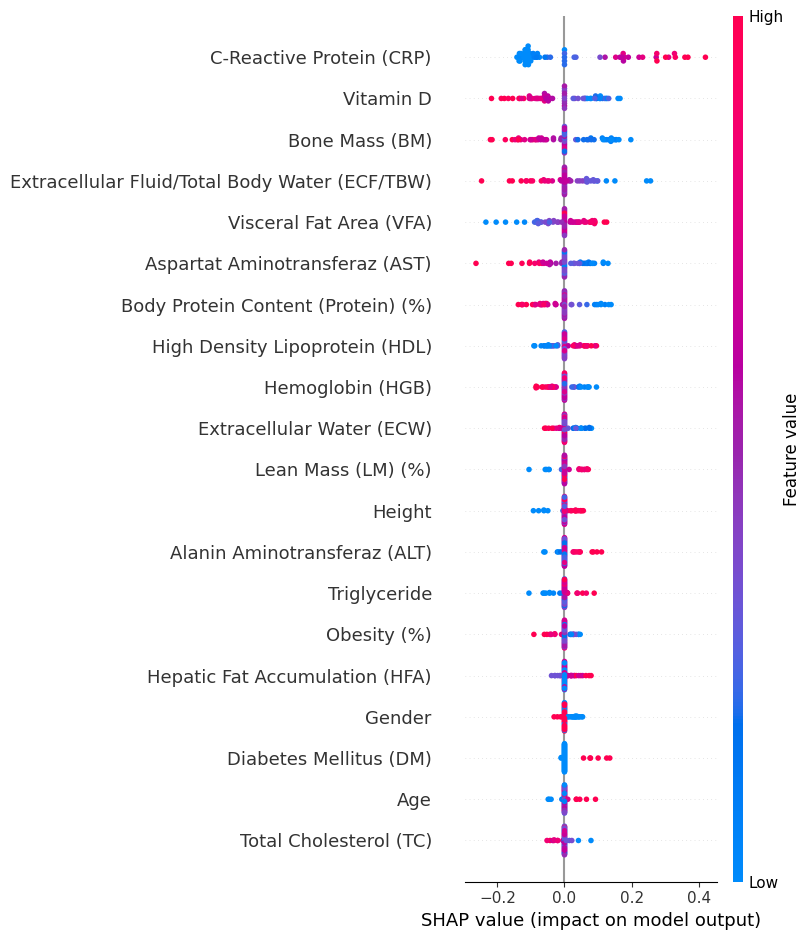

In [ ]:
# Convert test data to DataFrame with proper column names
X_te_df = pd.DataFrame(X_te, columns=X_train_log_uncor.columns)

# Define prediction function for SHAP (average probabilities from base models)
def model_predict(data):
    probs = []
    for estimator in voting_clf.model_.estimators_:
        # fitted models are in estimators_
        fitted_estimator = estimator
        if hasattr(fitted_estimator, "predict_proba"):
            probs.append(fitted_estimator.predict_proba(data)[:, 1])
    avg_proba = np.mean(probs, axis=0)
    return avg_proba

# Use a subset of training data as background
background = X_tr[np.random.choice(X_tr.shape[0], 100, replace=False)]

# Initialize SHAP KernelExplainer
import shap
explainer = shap.KernelExplainer(model_predict, background)

# Compute SHAP values
shap_values = explainer.shap_values(X_te_df)

# Plot summary
shap.summary_plot(shap_values, X_te_df, feature_names=X_train_log_uncor.columns)


In [ ]:
import pandas as pd
import numpy as np

# Compute mean absolute SHAP values per feature
shap_df = pd.DataFrame({
    'feature': X_train_log_uncor.columns,
    'mean_abs_shap': np.abs(shap_values).mean(axis=0)
})

# Sort descending by importance
shap_df = shap_df.sort_values(by='mean_abs_shap', ascending=False).reset_index(drop=True)

# Display table
print(shap_df)

# Optional: save as CSV for your paper
shap_df.to_csv("shap_feature_importance.csv", index=False)


                                           feature  mean_abs_shap
0                         C-Reactive Protein (CRP)       0.140953
1                                        Vitamin D       0.079873
2                                   Bone Mass (BM)       0.077496
3   Extracellular Fluid/Total Body Water (ECF/TBW)       0.052639
4                          Visceral Fat Area (VFA)       0.050229
5                   Aspartat Aminotransferaz (AST)       0.047377
6               Body Protein Content (Protein) (%)       0.044838
7                   High Density Lipoprotein (HDL)       0.028301
8                                 Hemoglobin (HGB)       0.024390
9                        Extracellular Water (ECW)       0.015818
10                              Lean Mass (LM) (%)       0.014029
11                                          Height       0.012668
12                    Alanin Aminotransferaz (ALT)       0.011976
13                                    Triglyceride       0.011520
14        

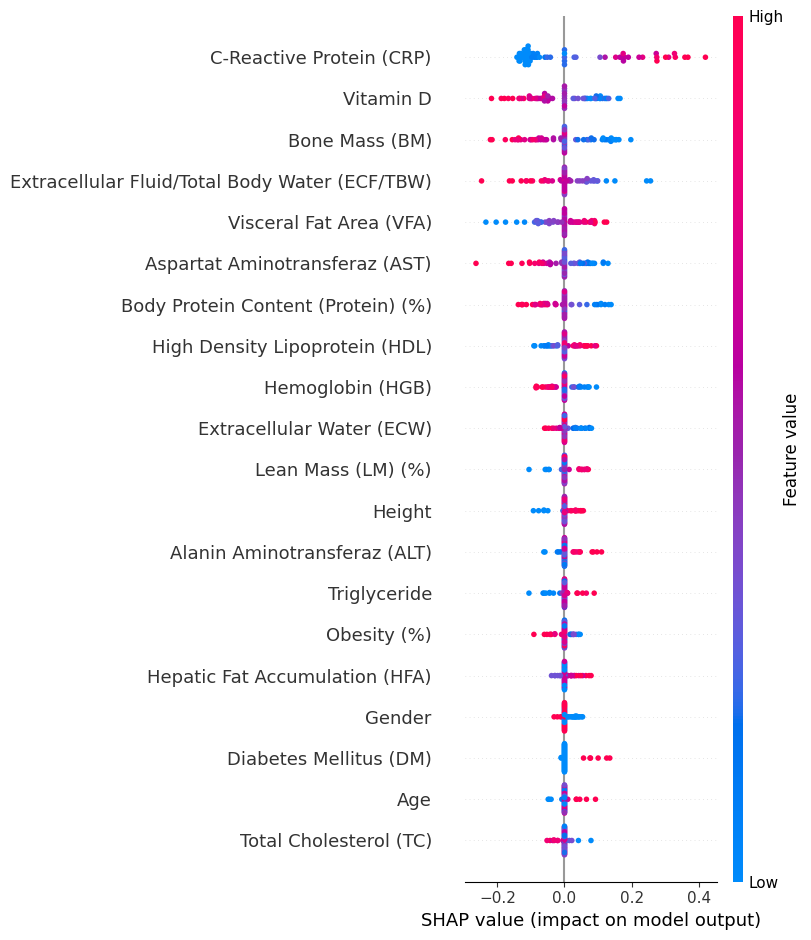

<Figure size 640x480 with 0 Axes>

In [ ]:
import shap
import matplotlib.pyplot as plt

# Color by feature values and order by importance
shap.summary_plot(
    shap_values,
    X_te_df,
    feature_names=X_train_log_uncor.columns,
    plot_type='dot',      # 'dot' or 'violin' for nice visualization
    max_display=20,        # top 20 features for clarity
    color=plt.get_cmap("coolwarm"),  # nice color gradient
    show=True
)

# Optional: save figure
plt.savefig("shap_summary_plot.png", dpi=300, bbox_inches='tight')


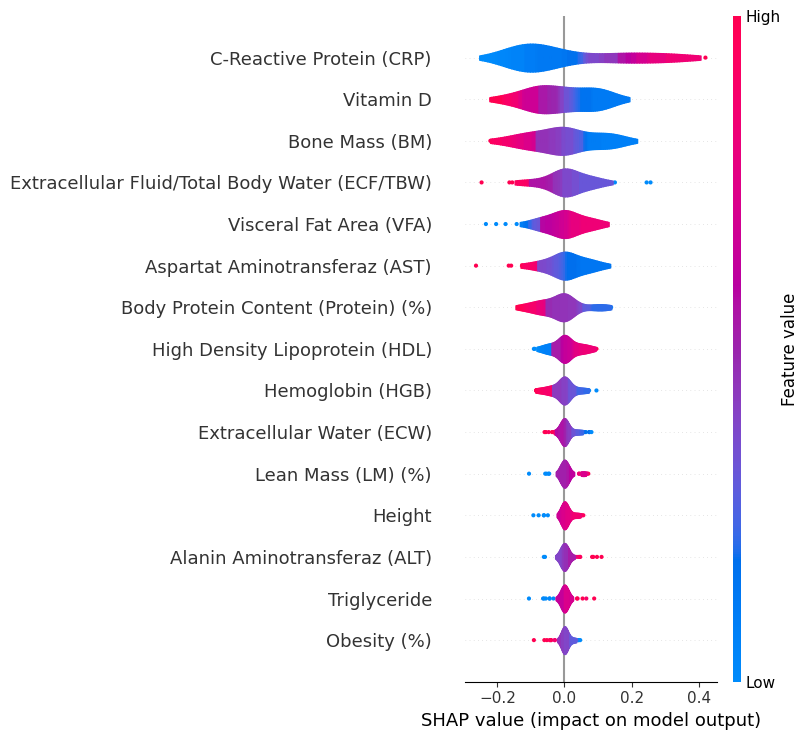

In [ ]:
shap.summary_plot(
    shap_values,
    X_te_df,
    feature_names=X_train_log_uncor.columns,
    plot_type='violin',
    max_display=15,
    color=plt.get_cmap("Spectral")
)


## (Experiment) Hybrid Stacking+Voting

In [ ]:
xgbc = xgb.XGBClassifier(random_state=42)
xgbc.fit(X_tr, y_tr)

prediction = xgbc.predict(X_te)
print(classification_report_row('XGBoost', y_test, prediction))

XGBoost                   | Accuracy: 0.8906 | Precision (0): 0.8824 | Recall (0): 0.9091 | F1-score (0): 0.8955 | Precision (1): 0.9000 | Recall (1): 0.8710 | F1-score (1): 0.8852


In [ ]:
# Get the misclassified indices again (since they were calculated in a previous cell)
misclassified_indices = np.where(prediction != y_test)[0]

# Get the misclassified data from the scaled and log-transformed test set
misclassified_X_te = X_te[misclassified_indices]

# Get the predicted probabilities for the misclassified data
# Assuming 'voting_clf' is the fitted VotingModel instance
misclassified_probabilities = xgbc.predict_proba(misclassified_X_te)

# Display the probabilities
print("Predicted probabilities for misclassified data points (Class 0, Class 1):")
display(misclassified_probabilities)

Predicted probabilities for misclassified data points (Class 0, Class 1):


array([[0.363755  , 0.636245  ],
       [0.84830767, 0.15169233],
       [0.08519441, 0.9148056 ],
       [0.61706185, 0.38293815],
       [0.04201764, 0.95798236],
       [0.9970355 , 0.00296448],
       [0.9868983 , 0.01310172]], dtype=float32)

In [ ]:
print(misclassified_indices)

[ 0  6  9 21 25 34 37]


In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# --- Your existing trained models ---
model_stackers = {
    'Logistic Regression',
    'Random Forest',
    'Gradient Boosting',
    'XGBoost',
    'Neural Network'
}

# --- Convert dict to list of (name, model) tuples for stacking ---
estimators = [(name, models[name]) for name in model_stackers]

# --- Define the meta learner ---
final_estimator = LogisticRegression(random_state=42)

# --- Create the stacking classifier ---
stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=final_estimator,
    cv=5,               # 5-fold CV for meta-learner training
    n_jobs=-1,          # use all cores
    passthrough=False   # if True, passes original features + base preds to meta-learner
)

# --- Train the stacking model ---
stacking_clf.fit(X_tr, y_tr)

# --- Evaluate on test set ---
y_pred = stacking_clf.predict(X_te)
acc = accuracy_score(y_te, y_pred)

print(f"Stacking Classifier Accuracy: {acc:.4f}")

Stacking Classifier Accuracy: 0.8594


## AutoML

In [ ]:
try:
  from flaml import AutoML
except:
  !pip install flaml -q
  from flaml import AutoML

from sklearn.metrics import accuracy_score

# Initialize AutoML
automl = AutoML()

# Train AutoML model
automl.fit(
    X_train=X_tr,
    y_train=y_tr,
    task="classification",   # or "regression" if your target is continuous
    time_budget=60,          # seconds to search for best model
    metric="accuracy"        # use "r2" for regression
)

# Make predictions on test data
y_pred = automl.predict(X_te)

# Evaluate
print("Test Accuracy:", accuracy_score(y_te, y_pred))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.2/322.2 kB 12.6 MB/s eta 0:00:00
[flaml.automl.logger: 12-20 06:20:49] {1752} INFO - task = classification
[flaml.automl.logger: 12-20 06:20:49] {1763} INFO - Evaluation method: cv
[flaml.automl.logger: 12-20 06:20:49] {1862} INFO - Minimizing error metric: 1-accuracy
[flaml.automl.logger: 12-20 06:20:49] {1979} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']
[flaml.automl.logger: 12-20 06:20:49] {2282} INFO - iteration 0, current learner lgbm


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[flaml.automl.logger: 12-20 06:20:50] {2417} INFO - Estimated sufficient time budget=9253s. Estimated necessary time budget=214s.
[flaml.automl.logger: 12-20 06:20:50] {2466} INFO -  at 1.0s,	estimator lgbm's best error=0.2667,	best estimator lgbm's best error=0.2667
[flaml.automl.logger: 12-20 06:20:50] {2282} INFO - iteration 1, current learner lgbm


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[flaml.automl.logger: 12-20 06:20:51] {2466} INFO -  at 1.4s,	estimator lgbm's best error=0.2667,	best estimator lgbm's best error=0.2667
[flaml.automl.logger: 12-20 06:20:51] {2282} INFO - iteration 2, current learner lgbm


...

[flaml.automl.logger: 12-20 06:20:55] {2466} INFO -  at 5.6s,	estimator sgd's best error=0.1961,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:55] {2282} INFO - iteration 18, current learner sgd
[flaml.automl.logger: 12-20 06:20:55] {2466} INFO -  at 5.7s,	estimator sgd's best error=0.1961,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:55] {2282} INFO - iteration 19, current learner sgd
[flaml.automl.logger: 12-20 06:20:55] {2466} INFO -  at 6.0s,	estimator sgd's best error=0.1961,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:55] {2282} INFO - iteration 20, current learner lgbm
[flaml.automl.logger: 12-20 06:20:56] {2466} INFO -  at 6.2s,	estimator lgbm's best error=0.2314,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:56] {2282} INFO - iteration 21, current learner sgd


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[flaml.automl.logger: 12-20 06:20:56] {2466} INFO -  at 6.4s,	estimator sgd's best error=0.1961,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:56] {2282} INFO - iteration 22, current learner sgd
[flaml.automl.logger: 12-20 06:20:56] {2466} INFO -  at 6.4s,	estimator sgd's best error=0.1961,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:56] {2282} INFO - iteration 23, current learner sgd
[flaml.automl.logger: 12-20 06:20:56] {2466} INFO -  at 6.5s,	estimator sgd's best error=0.1961,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:56] {2282} INFO - iteration 24, current learner sgd
[flaml.automl.logger: 12-20 06:20:56] {2466} INFO -  at 6.5s,	estimator sgd's best error=0.1961,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:56] {2282} INFO - iteration 25, current learner sgd
[flaml.automl.logger: 12-20 06:20:56] {2466} INFO -  at 6.6s,	estimator sgd's best error=0.1961,	best estimator 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

[flaml.automl.logger: 12-20 06:20:56] {2466} INFO -  at 6.9s,	estimator sgd's best error=0.1961,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:56] {2282} INFO - iteration 31, current learner sgd
[flaml.automl.logger: 12-20 06:20:56] {2466} INFO -  at 7.1s,	estimator sgd's best error=0.1961,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:56] {2282} INFO - iteration 32, current learner xgboost
[flaml.automl.logger: 12-20 06:20:56] {2466} INFO -  at 7.2s,	estimator xgboost's best error=0.2706,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:56] {2282} INFO - iteration 33, current learner xgboost
[flaml.automl.logger: 12-20 06:20:56] {2466} INFO -  at 7.2s,	estimator xgboost's best error=0.2706,	best estimator sgd's best error=0.1961
[flaml.automl.logger: 12-20 06:20:56] {2282} INFO - iteration 34, current learner xgboost
[flaml.automl.logger: 12-20 06:20:57] {2466} INFO -  at 7.3s,	estimator xgboost's best error

## Quantum SVC

In [ ]:
print(X_tr.shape, X_te.shape, y_tr.shape, y_te.shape)


(255, 35) (64, 35) (255,) (64,)


In [ ]:
# Train a Random Forest model to get feature importances
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_log_uncor, y_tr)

# Get feature importances
feature_importances = pd.Series(rf_model.feature_importances_, index=X_train_log_uncor.columns)

# Select top 8 features
top_8_features = feature_importances.nlargest(8).index.tolist()

print("Top 8 features based on Random Forest importance:")
print(top_8_features)

# Select the top 8 features from the training and testing data
X_tr_top8 = X_train_log_uncor[top_8_features].values
X_te_top8 = X_test_log_uncor[top_8_features].values

print(f"\nShape of X_tr_top8: {X_tr_top8.shape}")
print(f"Shape of X_te_top8: {X_te_top8.shape}")

Top 8 features based on Random Forest importance:
['Vitamin D', 'C-Reactive Protein (CRP)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Aspartat Aminotransferaz (AST)', 'High Density Lipoprotein (HDL)', 'Bone Mass (BM)', 'Extracellular Water (ECW)', 'Creatinine']

Shape of X_tr_top8: (255, 8)
Shape of X_te_top8: (64, 8)


In [ ]:
try:
  from qiskit_machine_learning.algorithms import PegasosQSVC
except:
  !pip install -q qiskit-machine-learning
  from qiskit_machine_learning.algorithms import PegasosQSVC

import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from qiskit_machine_learning.algorithms import PegasosQSVC
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit.circuit.library import ZZFeatureMap
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.state_fidelities import ComputeUncompute

# Reduce to 8 qubits (features) for safe simulation
pca = PCA(n_components=8)
X_tr_small = X_tr_top8
X_te_small = X_te_top8

print(f"X_tr_small shape: {X_tr_small.shape}")
print(f"X_te_small shape: {X_te_small.shape}")

# =========================
# Quantum Kernel with V2 primitives
# =========================
num_qubits = X_tr_small.shape[1]
feature_map = ZZFeatureMap(feature_dimension=num_qubits, reps=1)

sampler = StatevectorSampler()       # V2 primitive
fidelity = ComputeUncompute(sampler=sampler)

quantum_kernel = FidelityQuantumKernel(fidelity=fidelity, feature_map=feature_map)


# =========================
# PegasosQSVC
# =========================
C = 100
num_steps = 50
pegasos_qsvc = PegasosQSVC(quantum_kernel=quantum_kernel, C=C, num_steps=num_steps)

# =========================
# Training
# =========================
pegasos_qsvc.fit(X_tr_small, y_tr.values)

'''
# =========================
# Evaluation
# =========================
train_acc = pegasos_qsvc.score(X_tr_small, y_tr)
test_acc = pegasos_qsvc.score(X_te_small, y_te)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
'''


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.9/231.9 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.4/54.4 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 MB 11.0 MB/s eta 0:00:00
X_tr_small shape: (255, 8)
X_te_small shape: (64, 8)


'\n# =========================\n# Evaluation\n# =========================\ntrain_acc = pegasos_qsvc.score(X_tr_small, y_tr)\ntest_acc = pegasos_qsvc.score(X_te_small, y_te)\n\nprint(f"Training Accuracy: {train_acc:.4f}")\nprint(f"Test Accuracy: {test_acc:.4f}")\n'

In [ ]:
train_acc = pegasos_qsvc.score(X_tr_small, y_tr.values)
test_acc = pegasos_qsvc.score(X_te_small, y_te.values)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Training Accuracy: 0.5255
Test Accuracy: 0.5156


## Biological Optimization

In [ ]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.utils import check_random_state

# -----------------------------
# 1. Biological learning-like feature augmenter
# -----------------------------
class ProtoFeatures(BaseEstimator, TransformerMixin):
    """
    Prototype similarity feature generator (bio-inspired associative learning).
    Computes cosine similarity and negative Euclidean distance
    from each sample to class centroids.
    """
    def __init__(self):
        self.centroids_ = None

    def fit(self, X, y):
        classes = np.unique(y)
        self.centroids_ = np.stack([X[y == c].mean(axis=0) for c in classes])
        return self

    def transform(self, X):
        if self.centroids_ is None:
            raise RuntimeError("Call fit() first.")
        Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)
        Cn = self.centroids_ / (np.linalg.norm(self.centroids_, axis=1, keepdims=True) + 1e-9)
        cosine = Xn @ Cn.T
        dist = -np.linalg.norm(X[:, None, :] - self.centroids_[None, :, :], axis=2)
        return np.concatenate([X, cosine, dist], axis=1)

# -----------------------------
# 2. PSO optimizer for VotingModel weights
# -----------------------------
class BioSwarmOptimizer:
    """
    Simple PSO to tune VotingModel weights and threshold.
    Works with your existing VotingModel instance.
    """
    def __init__(self, n_particles=20, n_iter=40, inertia=0.7, c1=1.5, c2=1.5, random_state=None):
        self.n_particles = n_particles
        self.n_iter = n_iter
        self.w = inertia
        self.c1 = c1
        self.c2 = c2
        self.random_state = check_random_state(random_state)

    def optimize(self, model_class, X_train, y_train, X_val, y_val):
        n_models = 3  # Logistic, GB, MLP (from your VotingModel)
        dim = n_models + 1  # 3 weights + threshold
        lb, ub = 0.0, 1.0

        X = self.random_state.uniform(lb, ub, (self.n_particles, dim))
        V = self.random_state.normal(0, 0.1, (self.n_particles, dim))
        pbest = X.copy()
        pbest_score = np.full(self.n_particles, -np.inf)
        gbest = None
        gbest_score = -np.inf

        def fitness(vec):
            weights = vec[:-1]
            threshold = vec[-1]
            model = model_class(weights=weights, threshold=threshold)
            model.fit(X_train, y_train)
            preds = model.predict(X_val)
            return accuracy_score(y_val, preds)

        for it in range(self.n_iter):
            for i in range(self.n_particles):
                X[i] = np.clip(X[i], lb, ub)
                score = fitness(X[i])
                if score > pbest_score[i]:
                    pbest_score[i] = score
                    pbest[i] = X[i].copy()
                if score > gbest_score:
                    gbest_score = score
                    gbest = X[i].copy()

            # PSO velocity and position updates
            r1, r2 = self.random_state.rand(self.n_particles, dim), self.random_state.rand(self.n_particles, dim)
            cognitive = self.c1 * r1 * (pbest - X)
            social = self.c2 * r2 * (gbest - X)
            V = self.w * V + cognitive + social
            X += V

        best_weights, best_thresh = gbest[:-1], gbest[-1]
        print(f"✅ PSO best validation accuracy: {gbest_score:.4f}")
        print(f"Best weights: {np.round(best_weights, 3)} | Best threshold: {best_thresh:.3f}")
        return best_weights, best_thresh


In [ ]:
# === Step 2: add biological features ===
bl = ProtoFeatures()
X_tr_bl = bl.fit_transform(X_tr, y_tr)
X_te_bl = bl.transform(X_te)

# === Step 3: optimize ensemble weights with PSO ===
optimizer = BioSwarmOptimizer(n_particles=25, n_iter=40, random_state=42)

# Split a small validation set from training for PSO
from sklearn.model_selection import train_test_split
X_tr_sub, X_val, y_tr_sub, y_val = train_test_split(X_tr_bl, y_tr, test_size=0.2, stratify=y_tr, random_state=42)

best_w, best_thresh = optimizer.optimize(VotingModel, X_tr_sub, y_tr_sub, X_val, y_val)

# === Step 4: train final model ===
final_model = VotingModel(weights=best_w, threshold=best_thresh)
final_model.fit(X_tr_bl, y_tr)

# === Step 5: evaluate ===
train_acc = final_model.score(X_tr_bl, y_tr)
test_acc = final_model.score(X_te_bl, y_te)

print(f"Train accuracy: {train_acc:.4f}")
print(f"Test accuracy: {test_acc:.4f}")


✅ PSO best validation accuracy: 0.8431
Best weights: [0.899 0.208 0.251] | Best threshold: 0.218
Train accuracy: 0.8588
Test accuracy: 0.8125
